# MAE O3 · Choosing the action eight arrivals ahead with an MLP

**Finished both O3 horizon comparisons** · 2026-11-21T14:59:16+01:00

Calibration replay **8,000/8,000**. Held-out arrivals **{'t+8': 72000, 't+1': 72000}** of **72,000 per arm**. ETA **—** (Stockholm).

Both arms use the original single-image TinyMAE initialization, 88 causal features, and the same 128-image health bank refreshed every 96 arrivals. The utility is **−scaled reconstruction MSE + 0.25 × scaled RankMe**, with the original calibration scales.

Each predictor estimates the advantage of Skip, 0.25× or 1× at its horizon. For +8, the first action varies and the next seven training rates are fixed at 0.25× in the forecast target. The score is measured after the eighth arrival on its reconstruction and the slow bank's RankMe. Only the first action is executed. The predictor sees the current image and past observations. The last seven arrivals use the one-step head.

The +8 arm uses a frozen multi-output MLP with 48 and 24 hidden units. It predicts four metric advantages versus Skip for each of the two nonzero rates. The +1 arm keeps Lasso. Both share the paired calibration data from the first 8,000 arrivals, so the comparison changes both horizon and predictor family. Held-out audits branch after choosing the action and score the three alternatives with the same continuation. All measurements are label free.


## Calibration holdout (278 matched states)

| Horizon | MSE advantage RMSE | RankMe advantage RMSE | O3 regret | O3 gain vs 0.25× |
| --- | --- | --- | --- | --- |
 | +1 Lasso | 0.006836 | 0.002702 | 0.003350 | +0.030061 | 
 | +8 MLP | 0.003865 | 0.003387 | 0.001462 | +0.022215 | 

**MLP fit** Stochastic Optimizer: Maximum iterations (60) reached and the optimization hasn't converged yet.

## Closed-loop comparison

| Policy | Stream MSE | Stream RankMe | Stream O3 cost ↓ | Test MSE | Test RankMe | Test O3 cost ↓ | Skip / 0.25× / 1× |
| --- | --- | --- | --- | --- | --- | --- | --- |
 | t+8 | 0.801613 | 3.19699 | 2.036190 | 0.917865 | 3.30991 | 2.652410 | 1906 / 6702 / 63392 | 
 | t+1 | 0.844665 | 2.53621 | 2.907326 | 0.931449 | 3.55312 | 2.513946 | 3633 / 14033 / 54334 | 

## Paired action audits during deployment

| Policy | States | MSE advantage RMSE | RankMe advantage RMSE | Own-horizon O3 regret | +8 O3 gain vs 0.25× |
| --- | --- | --- | --- | --- | --- |
 | t+8 | 48 | 0.007192 | 0.013954 | 0.002708 | +0.011953 | 
 | t+1 | 48 | 0.015703 | 0.010834 | 0.006233 | +0.005899 | 

## Run trajectories

Each point averages up to 1,024 saved arrivals. The O3 utility is the negative of the O3 cost in the results table. Rerun the plot cell to refresh from the latest checkpoint.

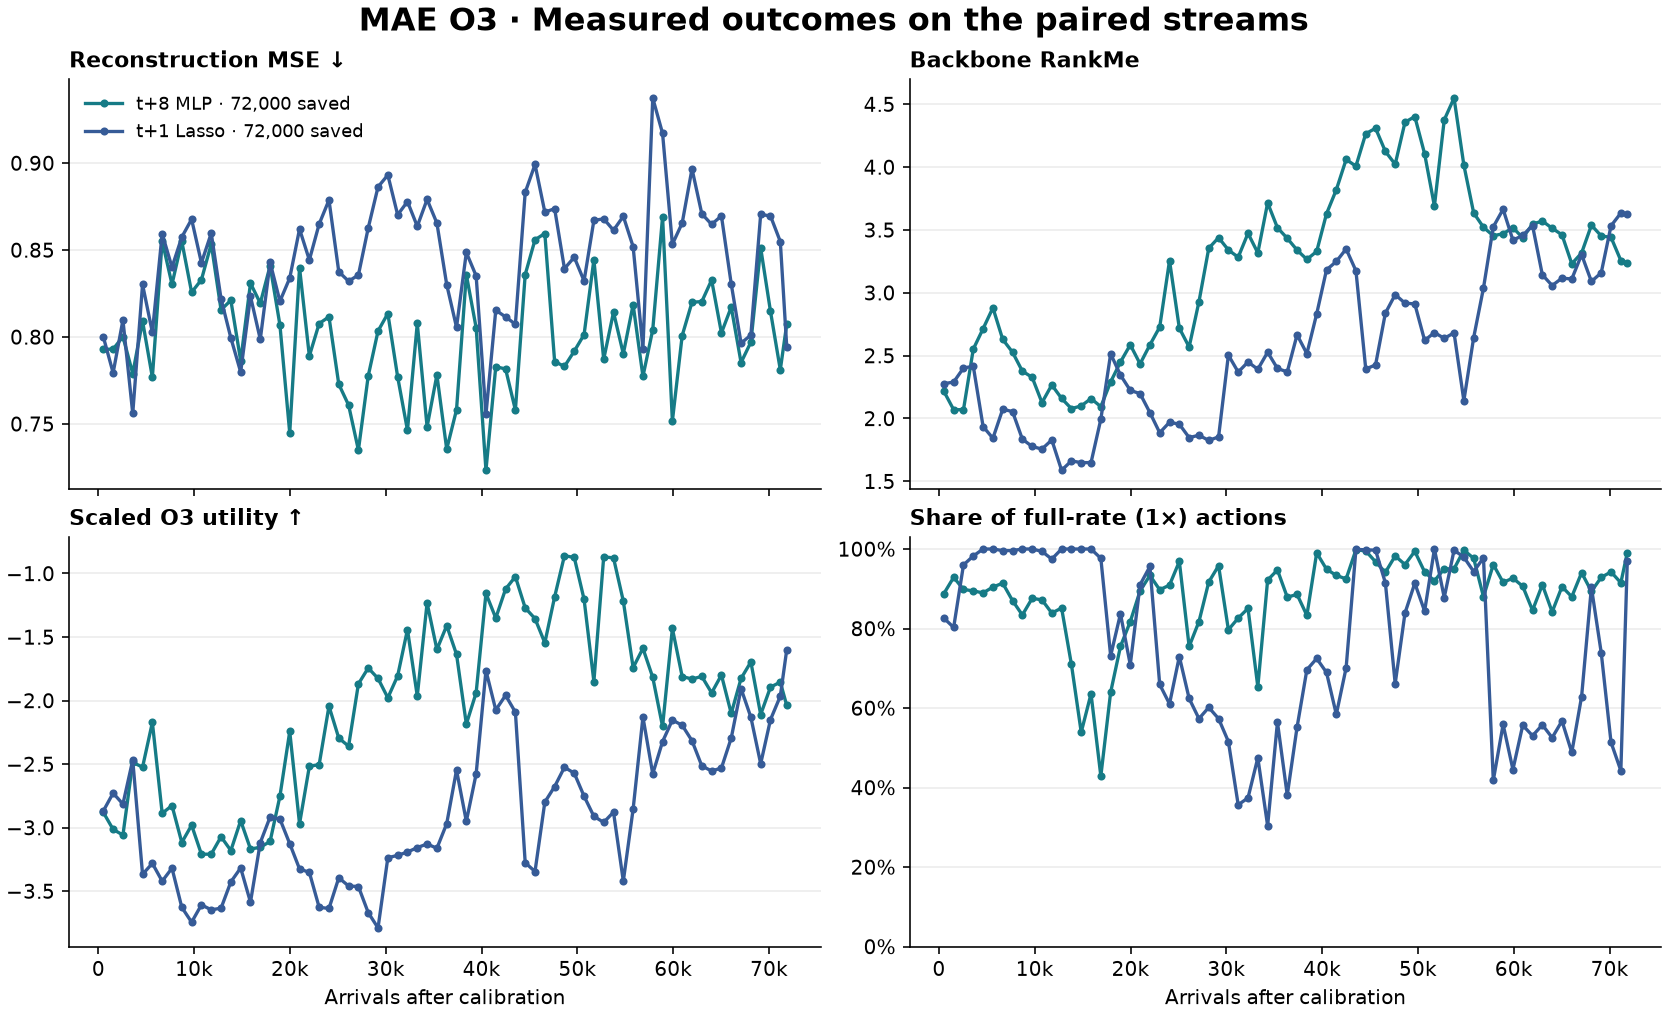

In [ ]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt

folder = Path('C:/CAFL-E/analysis/2026-11-09-one-step-mpc/o3-horizon8-mlp')
sys.path.insert(0, str(folder.parent))
from o3_horizon8_plot import plot_run

figure = plot_run(folder)
if figure is not None:
    display(figure)
    plt.close(figure)
